In [2]:
import scipy as sp
import matplotlib.pyplot as plt
from singingmaterials import dos_stats
import csv
import numpy as np

In [ ]:
def peak_finder(mp_id,temp,height,prominence):
    if temp == "athermal":
        data = dos_stats.dos_stats_analysis(mp_id=mp_id)
        density = data["projection"]["total"]["stats"]["athermal"]["densities"]
    else:
        data = dos_stats.dos_stats_analysis(mp_id=mp_id, temp=temp)
        density = data["projection"]["total"]["stats"]["thermal"][str(temp)]["densities"]
    frequency = data["projection"]["total"]["frequencies"]
    peak_indices, peak_properties = sp.signal.find_peaks(density, height=height, prominence=prominence)

    plt.plot(frequency, density)
    plt.scatter(frequency[peak_indices], density[peak_indices], color='red', zorder=5)
    plt.xlabel("Frequency")
    plt.ylabel("Density")
    plt.title("Density of States")
    plt.show()

    return data, peak_indices, peak_properties


# write a function to save peak data to a CSV file
def save_peak_data(mp_id, temp, peak_indices, peak_properties, frequency):
    ref_index = np.argmax(peak_properties["peak_heights"])
    dos_ratios = peak_properties["peak_heights"] / peak_properties["peak_heights"][ref_index]
    norm_dos_ratios = dos_ratios / np.sum(dos_ratios)
    freq_ratios = frequency[peak_indices] / frequency[peak_indices][ref_index]

    with open(f"peak_data_{mp_id}_{temp}.csv", "w", newline="") as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow([f"# mp_id: {mp_id}"])
        writer.writerow(["Peak Index", "Peak Height", "Frequency", "DOS Ratio", "Normalized DOS Ratio", "Frequency Ratio"])
        for i, peak_index in enumerate(peak_indices):
            writer.writerow([
                peak_index,
                peak_properties["peak_heights"][i],
                frequency[peak_index],
                dos_ratios[i],
                norm_dos_ratios[i],
                freq_ratios[i]
            ])



Fetching from existing file...


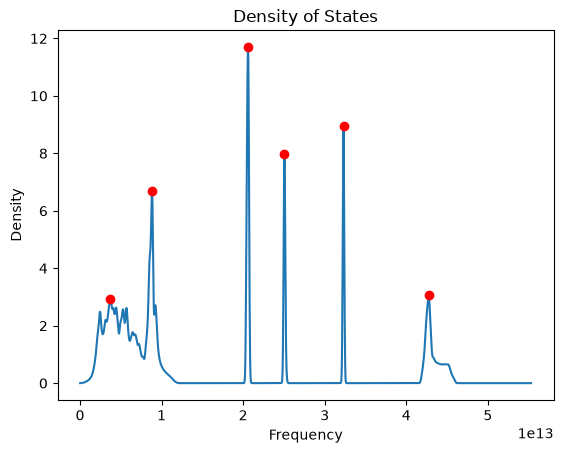

In [11]:
mp_id = "mp-3953"
temp = "athermal"
height = 2.5
prominence = 1
data, peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])



Fetching from existing file...


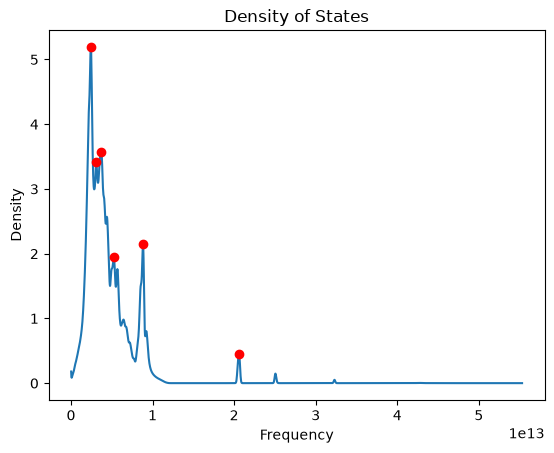

In [12]:
mp_id = "mp-3953"
temp = 300
height = 0.1
prominence = 0.3
data, peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


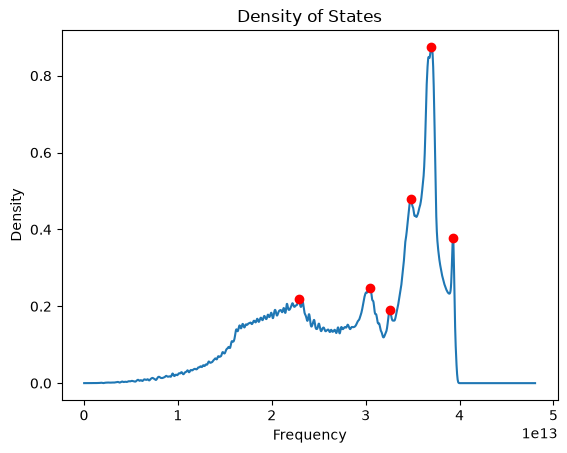

In [13]:
mp_id = "mp-66"
temp = "athermal"
height = 0.1
prominence = 0.02
data, peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


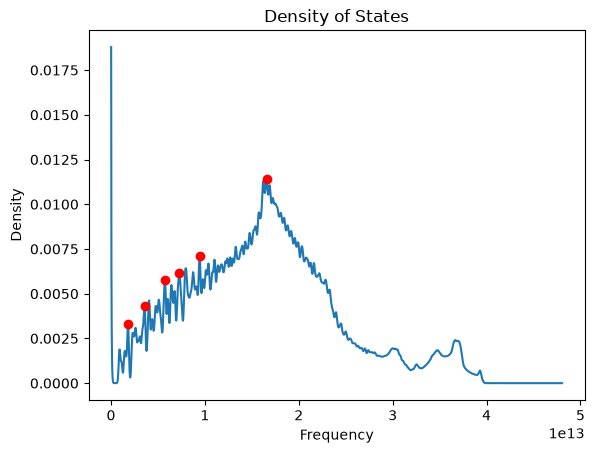

In [14]:
mp_id = "mp-66"
temp = 300
height = 1E-5
prominence = 0.002
data, peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


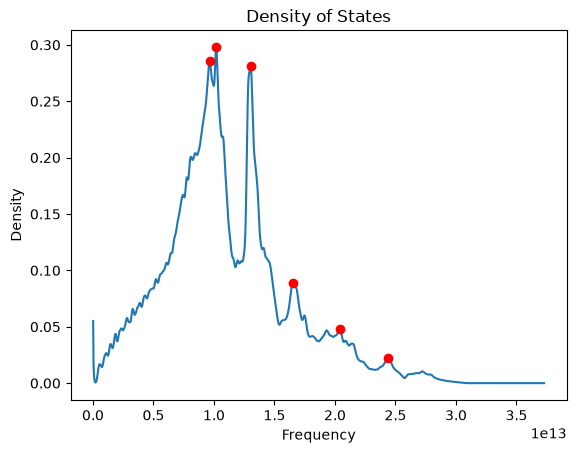

In [16]:
mp_id = "mp-6947"
temp = 300
height = 1E-5
prominence = 0.01
data,peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


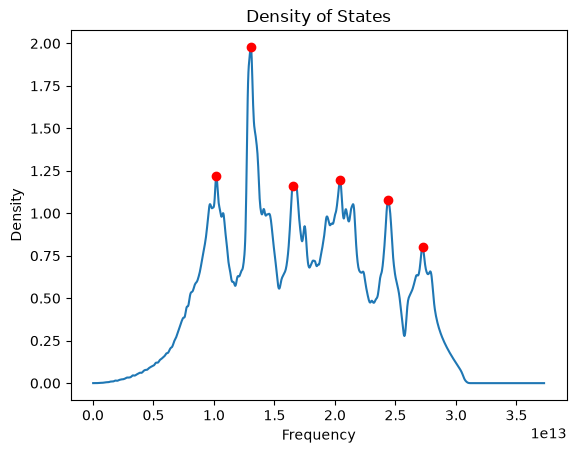

In [19]:
mp_id = "mp-6947"
temp = "athermal"
height = 1E-5
prominence = 0.12
data,peak_indices, peak_properties = peak_finder(mp_id, temp, height, prominence)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

## TODO:

- Set prominence to something small (might need to be determined by the DOS amplitude) and then select the peaks with the top X amplitudes, to avoid visual inspection step.
- Integrate into SingingMaterials, think about which data I want to store and where.